# 论文原值参照：Size and value in China

**本文件状态：原文数值转录。** `paper_targets` 保存 Liu、Stambaugh 与 Yuan（2019），*Journal of Financial Economics* 134, 48–69 的全部正文 Table 1–10 与 Appendix Table A1–A5。来源是工作区 `参考论文/Size and value in China.pdf`，22 页；下文同时记录 PDF 页码和期刊页码。

这里的数值只用于后续复现结果的逐格比较。读取本文件不会读取行情数据、生成因子或运行实证回归；原表中的空项保存为 `NaN`，不会以零替代。除 Table 1 的斜率已经乘 100、Table 2/A3 斜率保持原文小数外，收益均值、标准差和 alpha 的单位为月度百分数，beta、t、R²、相关系数、GRS 与 p 值无量纲。

用户本轮已授权直接完成 notebook；本文件仅新增原文参照对象。

【表状态：论文排版表 → 原文参照长表（S_target）】

- 粒度：一项表格统计量。
- 主键：每个表内 `(panel, row, metric)` 唯一。
- 行数：宽表的一格转为一行；未报告的回归项显式保留空值。
- 列：统一为 `panel`、`row`、`metric`、`paper_value`。
- 索引：普通整数索引；键保留在列中，方便与复现长表合并。
- 时间：一般为 2000-01 至 2016-12（204 月）；Table 1 的美国样本为 1980–2016，A2 为 2007–2016。
- 下游：比较 notebook；参照值不能替代 S0–S9 数据生产链。


In [ ]:
# 【正式工程准入】本轮用户已授权直接完成；此处仅定义原文参照常量
import pandas as pd
import numpy as np

paper_targets = {}
paper_source = '参考论文/Size and value in China.pdf'

# 一行排版数据中多个统计量 → 每个统计量一行，键全部保留为列
# 此函数不估计任何统计量，也不修改论文值
def get_target_long(panel , rows , metrics , values):
    wide = pd.DataFrame(values , index = rows , columns = metrics)
    wide.index.name = 'row'
    target = wide.reset_index().melt(
        id_vars = 'row' , var_name = 'metric' , value_name = 'paper_value'
    )
    target.insert(0 , 'panel' , panel)
    target['paper_value'] = pd.to_numeric(target['paper_value'] , errors = 'raise')
    return target[['panel' , 'row' , 'metric' , 'paper_value']]

anomaly_rows = [
    'size' , 'ep' , 'bm' , 'cp' , 'roe' , 'volatility' ,
    'max' , 'reversal' , 'turnover' , 'abnormal_turnover'
]


## Table 1：盈余公告反应（PDF 7 / 期刊 54）

`panel` 是 `k0_china`、`k0_us`、`k3_china`、`k3_us`；`row` 为 `smallest`、`middle`、`largest`。`beta` 是论文的 b×100，`t_beta` 为 White t 值，`r2` 为原文小数。中国组别使用前月市值底部 30%、中间 40%、顶部 30%；SUE 使用过去八季的同比盈余变化标准差。


In [ ]:
paper_targets['table1'] = pd.concat([
    get_target_long('k0_china' , ['smallest' , 'middle' , 'largest'] , ['beta' , 't_beta' , 'r2'] , [
        [0.14 , 6.34 , 0.003] , [0.17 , 12.42 , 0.010] , [0.24 , 17.28 , 0.017]
    ]) ,
    get_target_long('k0_us' , ['smallest' , 'middle' , 'largest'] , ['beta' , 't_beta' , 'r2'] , [
        [0.19 , 7.51 , 0.005] , [0.07 , 6.99 , 0.003] , [0.05 , 9.90 , 0.002]
    ]) ,
    get_target_long('k3_china' , ['smallest' , 'middle' , 'largest'] , ['beta' , 't_beta' , 'r2'] , [
        [0.43 , 9.74 , 0.006] , [0.58 , 17.91 , 0.016] , [0.59 , 17.60 , 0.021]
    ]) ,
    get_target_long('k3_us' , ['smallest' , 'middle' , 'largest'] , ['beta' , 't_beta' , 'r2'] , [
        [0.52 , 7.84 , 0.012] , [0.20 , 6.03 , 0.005] , [0.13 , 10.68 , 0.003]
    ])
] , ignore_index = True)


## Table 2：Fama–MacBeth 特征回归（PDF 7 / 期刊 54）

每个规格 `(1)`–`(9)` 是一个 `panel`；`estimate` 与 `t` 分开。`adj_r2` 行没有 t 值，未纳入某规格的变量没有估计值和 t 值。EP/CP 的正值项与负值指示项分别是 `ep_pos`/`ep_neg`、`cp_pos`/`cp_neg`。beta 用前 12 月日收益、五个滞后 Dimson 修正；斜率均值的 t 值使用 Newey–West 四阶滞后。下列值保持原文小数，不乘 100。


In [ ]:
fm_rows = ['intercept' , 'beta' , 'log_me' , 'log_bm' , 'log_am' ,
           'ep_pos' , 'ep_neg' , 'cp_pos' , 'cp_neg' , 'adj_r2']
# 每个变量的九个位置严格对应原表 (1) 至 (9)
fm_estimate = [
    [0.0149 , 0.0581 , 0.0571 , 0.0659 , 0.0629 , 0.0690 , 0.0564 , 0.0716 , 0.0728] ,
    [-0.0002 , np.nan , -0.0010 , -0.0018 , -0.0017 , 0.0002 , -0.0010 , -0.0002 , -0.0004] ,
    [np.nan , -0.0049 , -0.0046 , -0.0046 , -0.0048 , -0.0068 , -0.0047 , -0.0066 , -0.0064] ,
    [np.nan , np.nan , np.nan , 0.0057 , np.nan , np.nan , np.nan , 0.0022 , 0.0035] ,
    [np.nan , np.nan , np.nan , np.nan , 0.0045 , np.nan , np.nan , 0.0014 , np.nan] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , 0.9503 , np.nan , 0.7825 , 0.7960] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , 0.0006 , np.nan , -0.0005 , -0.0001] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , np.nan , 0.0546 , 0.0181 , np.nan] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , np.nan , 0.0019 , 0.0016 , np.nan] ,
    [0.0196 , 0.0277 , 0.0441 , 0.0652 , 0.0677 , 0.0615 , 0.0454 , 0.0832 , 0.0776]
]
fm_t = [
    [1.94 , 3.32 , 3.19 , 3.90 , 3.74 , 4.03 , 3.19 , 4.40 , 4.39] ,
    [-0.09 , np.nan , -0.37 , -0.71 , -0.67 , 0.07 , -0.37 , -0.06 , -0.15] ,
    [np.nan , -2.91 , -2.69 , -2.73 , -3.00 , -4.34 , -2.80 , -4.49 , -4.40] ,
    [np.nan , np.nan , np.nan , 3.21 , np.nan , np.nan , np.nan , 1.31 , 1.76] ,
    [np.nan , np.nan , np.nan , np.nan , 3.03 , np.nan , np.nan , 0.99 , np.nan] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , 4.88 , np.nan , 4.38 , 5.06] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , 0.31 , np.nan , -0.29 , -0.04] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , np.nan , 3.41 , 1.35 , np.nan] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , np.nan , 3.11 , 2.37 , np.nan] ,
    [np.nan] * 9
]
paper_targets['table2'] = pd.concat([
    get_target_long('({})'.format(j + 1) , fm_rows , ['estimate' , 't'] ,
                    [[fm_estimate[i][j] , fm_t[i][j]] for i in range(len(fm_rows))])
    for j in range(9)
] , ignore_index = True)


## Table 3–4：因子描述与解释收益方差（PDF 8–9 / 期刊 55–56）

Table 3 的 `mean` 与 `std` 是月度百分数；`t_mean` 与成对相关系数保持原文值。Table 4 的 `r2` 保持小数，`china_all` 包含最小 30%，`china_top70` 排除最小 30%，`us` 是美国共同股票；各个股票先做 36 月滚动回归，再分别对时间和股票取均值。`mkt_value` 在美国使用 HML，在中国使用 VMG。


In [ ]:
paper_targets['table3'] = get_target_long(
    'main' , ['mkt' , 'smb' , 'vmg'] ,
    ['mean' , 'std' , 't_mean' , 'corr_mkt' , 'corr_smb' , 'corr_vmg'] , [
        [0.66 , 8.09 , 1.16 , 1.00 , 0.12 , -0.27] ,
        [1.03 , 4.52 , 3.25 , 0.12 , 1.00 , -0.62] ,
        [1.14 , 3.75 , 4.34 , -0.27 , -0.62 , 1.00]
    ]
)
paper_targets['table4'] = pd.concat([
    get_target_long(panel , ['mkt' , 'mkt_smb' , 'mkt_value' , 'three_factor'] , ['r2'] ,
                    [[value] for value in values])
    for panel , values in [
        ('china_all' , [0.385 , 0.507 , 0.471 , 0.536]) ,
        ('china_top70' , [0.417 , 0.528 , 0.501 , 0.562]) ,
        ('us' , [0.177 , 0.231 , 0.226 , 0.273])
    ]
] , ignore_index = True)


## Table 5：CH-3 与 FF-3 互相定价（PDF 10 / 期刊 57）

行 ID `ffsmb`/`ffhml` 是 FF-3 因子，`smb`/`vmg` 是 CH-3 因子；GRS 行 `ffsmb_ffhml` 和 `smb_vmg` 代表联合被解释因子集合。`alpha_ch3` 指该行收益在 CH-3 下的 alpha，FF-3 类似。原表横线保留 NaN，不把自己的因子作为额外回归来填值。FF-3 的 GRS p 值 `2.14e-13` 是原文精确印刷值，不是删失边界。


In [ ]:
paper_targets['table5'] = pd.concat([
    get_target_long('alpha' , ['ffsmb' , 'ffhml' , 'smb' , 'vmg'] ,
                    ['alpha_ch3' , 't_alpha_ch3' , 'alpha_ff3' , 't_alpha_ff3'] , [
        [-0.04 , -0.66 , np.nan , np.nan] , [0.34 , 0.97 , np.nan , np.nan] ,
        [np.nan , np.nan , 0.47 , 7.03] , [np.nan , np.nan , 1.39 , 7.93]
    ]) ,
    get_target_long('grs' , ['ffsmb_ffhml' , 'smb_vmg'] ,
                    ['grs_ch3' , 'p_ch3' , 'grs_ff3' , 'p_ff3'] , [
        [0.88 , 0.41 , np.nan , np.nan] , [np.nan , np.nan , 33.90 , 2.14e-13]
    ])
] , ignore_index = True)


## Table 6：十项异象的 CAPM 结果（PDF 12 / 期刊 59）

`unconditional` 为单变量十分位排序，`size_neutral` 为先市值十分位、再每组信号十分位，最后将各市值组同一信号分位的股票合并并按股票市值加权。Table 6–8/10 的市值中性 panel 省略 size；参照长表显式添加其空项，保留同一个行集合。`reversal` 是一个月反转，`turnover` 是过去十二月换手率，`abnormal_turnover` 是一个月相对十二月的换手率。Table 6 将十二月换手率误列在 Reversal 分类，后续表列在 Turnover；行 ID 仍按其指标本义。


In [ ]:
capm_metrics = ['mean' , 'alpha' , 'beta_mkt' , 't_mean' , 't_alpha' , 't_beta_mkt']
capm_unconditional = [
    [1.09 , 0.97 , 0.18 , 1.92 , 1.81 , 1.90] ,
    [1.27 , 1.37 , -0.16 , 2.58 , 2.93 , -2.15] ,
    [1.14 , 1.14 , 0.01 , 2.08 , 2.13 , 0.06] ,
    [0.73 , 0.70 , 0.04 , 1.67 , 1.69 , 0.55] ,
    [0.83 , 0.93 , -0.15 , 1.77 , 2.11 , -2.09] ,
    [0.81 , 1.03 , -0.34 , 1.64 , 2.31 , -5.55] ,
    [0.57 , 0.81 , -0.36 , 1.26 , 2.02 , -6.39] ,
    [1.47 , 1.49 , -0.02 , 2.96 , 3.06 , -0.22] ,
    [0.33 , 0.53 , -0.29 , 0.63 , 1.09 , -3.46] ,
    [1.14 , 1.27 , -0.19 , 2.44 , 2.92 , -2.66]
]
capm_size_neutral = [
    [np.nan] * 6 ,
    [1.80 , 1.89 , -0.14 , 4.32 , 4.72 , -2.25] ,
    [1.14 , 1.10 , 0.05 , 2.23 , 2.22 , 0.64] ,
    [0.78 , 0.76 , 0.04 , 2.27 , 2.25 , 0.71] ,
    [1.45 , 1.50 , -0.07 , 3.90 , 4.11 , -1.30] ,
    [0.66 , 0.90 , -0.37 , 1.41 , 2.19 , -6.20] ,
    [0.39 , 0.60 , -0.32 , 0.93 , 1.61 , -6.14] ,
    [1.67 , 1.65 , 0.02 , 3.65 , 3.68 , 0.32] ,
    [0.51 , 0.74 , -0.34 , 1.06 , 1.74 , -4.94] ,
    [1.29 , 1.39 , -0.15 , 3.19 , 3.68 , -2.56]
]
paper_targets['table6'] = pd.concat([
    get_target_long('unconditional' , anomaly_rows , capm_metrics , capm_unconditional) ,
    get_target_long('size_neutral' , anomaly_rows , capm_metrics , capm_size_neutral)
] , ignore_index = True)


## Table 7：CH-3 异象回归（PDF 12 / 期刊 59）

斜率与对应 White t 值各占一个 metric；`beta_vmg` 是 EP 价值因子的斜率。这里保留所有原表符号，不能由论文字面“解释”结论反推数值。


In [ ]:
ch3_metrics = ['alpha' , 'beta_mkt' , 'beta_smb' , 'beta_vmg' ,
               't_alpha' , 't_beta_mkt' , 't_beta_smb' , 't_beta_vmg']
ch3_unconditional = [
    [0.21 , 0.01 , 1.45 , -0.54 , 1.71 , 0.77 , 40.88 , -11.70] ,
    [0.04 , 0.04 , -0.38 , 1.40 , 0.16 , 1.31 , -4.73 , 14.75] ,
    [0.64 , 0.06 , -0.03 , 0.43 , 1.02 , 0.65 , -0.14 , 1.64] ,
    [0.20 , 0.14 , -0.28 , 0.64 , 0.45 , 2.10 , -1.95 , 4.00] ,
    [-0.36 , 0.03 , -0.29 , 1.28 , -0.88 , 0.70 , -2.35 , 9.43] ,
    [0.23 , -0.23 , -0.12 , 0.75 , 0.44 , -3.81 , -0.67 , 3.86] ,
    [0.27 , -0.30 , -0.05 , 0.48 , 0.65 , -4.57 , -0.30 , 2.55] ,
    [0.93 , -0.06 , 0.56 , 0.01 , 1.70 , -0.69 , 3.15 , 0.03] ,
    [0.42 , -0.14 , -0.85 , 0.77 , 1.30 , -3.69 , -9.33 , 7.90] ,
    [1.28 , -0.22 , 0.18 , -0.16 , 2.86 , -2.78 , 0.93 , -0.76]
]
ch3_size_neutral = [
    [np.nan] * 8 ,
    [0.23 , 0.02 , 0.05 , 1.32 , 0.82 , 0.47 , 0.57 , 11.97] ,
    [0.61 , 0.13 , -0.15 , 0.53 , 0.98 , 1.60 , -0.80 , 2.19] ,
    [0.18 , 0.11 , -0.06 , 0.52 , 0.54 , 1.98 , -0.50 , 3.84] ,
    [-0.37 , 0.05 , 0.41 , 1.20 , -1.04 , 1.23 , 4.14 , 9.66] ,
    [0.20 , -0.28 , -0.08 , 0.64 , 0.42 , -4.96 , -0.49 , 3.34] ,
    [0.00 , -0.26 , 0.05 , 0.45 , 0.00 , -4.38 , 0.30 , 2.50] ,
    [1.13 , 0.01 , 0.41 , 0.10 , 2.12 , 0.11 , 2.59 , 0.55] ,
    [0.25 , -0.22 , -0.43 , 0.74 , 0.69 , -4.94 , -3.91 , 5.74] ,
    [1.24 , -0.18 , 0.25 , -0.08 , 3.04 , -2.79 , 1.55 , -0.43]
]
paper_targets['table7'] = pd.concat([
    get_target_long('unconditional' , anomaly_rows , ch3_metrics , ch3_unconditional) ,
    get_target_long('size_neutral' , anomaly_rows , ch3_metrics , ch3_size_neutral)
] , ignore_index = True)


## Table 8：FF-3 异象回归（PDF 14 / 期刊 61）

`beta_smb`/`beta_hml` 在本表分别表示 FFSMB/FFHML；不会把 BM 价值因子改称 VMG。原表标题为 FF-3，但说明第一句写 CH-3；这里按照标题与回归方程记录模型，同时保留这项原文不一致的提示。


In [ ]:
ff3_metrics = ['alpha' , 'beta_mkt' , 'beta_smb' , 'beta_hml' ,
               't_alpha' , 't_beta_mkt' , 't_beta_smb' , 't_beta_hml']
ff3_unconditional = [
    [0.16 , 0.04 , 1.55 , -0.11 , 1.36 , 1.86 , 34.29 , -2.43] ,
    [1.54 , -0.07 , -0.98 , 0.48 , 5.57 , -1.63 , -13.29 , 6.54] ,
    [-0.28 , 0.00 , 0.12 , 1.60 , -1.25 , 0.09 , 1.48 , 30.61] ,
    [0.63 , 0.08 , -0.49 , 0.43 , 1.40 , 1.31 , -3.84 , 2.31] ,
    [1.75 , -0.06 , -1.01 , -0.28 , 5.67 , -1.36 , -12.74 , -3.08] ,
    [0.83 , -0.30 , -0.40 , 0.52 , 2.11 , -5.41 , -3.07 , 4.18] ,
    [0.74 , -0.33 , -0.28 , 0.28 , 1.85 , -5.70 , -1.79 , 1.96] ,
    [0.94 , -0.06 , 0.53 , 0.28 , 1.97 , -0.83 , 3.50 , 1.58] ,
    [0.83 , -0.19 , -1.08 , 0.38 , 2.96 , -4.97 , -13.10 , 3.72] ,
    [1.34 , -0.21 , 0.16 , -0.20 , 2.86 , -2.76 , 0.95 , -0.99]
]
ff3_size_neutral = [
    [np.nan] * 8 ,
    [1.76 , -0.09 , -0.53 , 0.52 , 5.49 , -1.79 , -6.52 , 6.17] ,
    [-0.01 , 0.07 , -0.10 , 1.39 , -0.04 , 1.75 , -1.36 , 20.12] ,
    [0.52 , 0.06 , -0.23 , 0.44 , 1.73 , 1.33 , -2.33 , 4.05] ,
    [2.01 , -0.04 , -0.36 , -0.35 , 5.72 , -0.71 , -3.75 , -3.38] ,
    [0.76 , -0.33 , -0.33 , 0.40 , 2.06 , -6.04 , -2.64 , 3.47] ,
    [0.43 , -0.30 , -0.16 , 0.31 , 1.14 , -5.67 , -1.10 , 2.60] ,
    [1.21 , -0.01 , 0.35 , 0.29 , 2.55 , -0.09 , 2.63 , 1.78] ,
    [0.80 , -0.28 , -0.68 , 0.39 , 2.46 , -5.89 , -6.37 , 3.74] ,
    [1.37 , -0.17 , 0.21 , -0.12 , 3.26 , -2.82 , 1.43 , -0.68]
]
paper_targets['table8'] = pd.concat([
    get_target_long('unconditional' , anomaly_rows , ff3_metrics , ff3_unconditional) ,
    get_target_long('size_neutral' , anomaly_rows , ff3_metrics , ff3_size_neutral)
] , ignore_index = True)


## Table 9：模型联合比较（PDF 14 / 期刊 61）

`grs_all`/`p_all` 在 unconditional 使用十项异象，在 size_neutral 使用九项异象；`grs7`/`p7` 排除构造因子使用的 size、BM、EP。原表说明声称还报告“最小绝对 alpha 的异象个数”，实际印刷数值表未提供该行；这里不自行补数。

**删失 p 值约定：**原文 `<0.0001` 在 `paper_value` 中保存上界 `0.0001`，真实 p 值未知。`paper_value_notes` 记录关系符 `<`，不能把这些上界当作精确观察值。原表其余印刷 `0.0001` 是按精度报告的数值，与 `<0.0001` 区别保留。


In [ ]:
comparison_metrics = ['avg_abs_alpha' , 'avg_abs_t' , 'grs_all' , 'p_all' , 'grs7' , 'p7']
model_rows = ['unadjusted' , 'capm' , 'ff3' , 'ch3']
paper_targets['table9'] = pd.concat([
    get_target_long('unconditional' , model_rows , comparison_metrics , [
        [0.94 , 1.89 , 7.30 , 0.0001 , 4.40 , 0.0002] ,
        [1.02 , 2.21 , 7.31 , 0.0001 , 4.45 , 0.0001] ,
        [0.90 , 2.70 , 6.00 , 0.0001 , 6.86 , 0.0001] ,
        [0.45 , 1.12 , 1.49 , 0.15 , 1.74 , 0.10]
    ]) ,
    get_target_long('size_neutral' , model_rows , comparison_metrics , [
        [1.08 , 2.55 , 8.24 , 0.0001 , 8.15 , 0.0001] ,
        [1.17 , 2.91 , 8.08 , 0.0001 , 8.10 , 0.0001] ,
        [0.99 , 2.72 , 7.97 , 0.0001 , 9.11 , 0.0001] ,
        [0.47 , 1.07 , 1.97 , 0.05 , 2.33 , 0.03]
    ])
] , ignore_index = True)
paper_value_notes = pd.DataFrame([
    {'table' : 'table9' , 'panel' : panel , 'row' : row , 'metric' : metric ,
     'relation' : '<' , 'bound' : 0.0001 , 'printed_value' : '<0.0001'}
    for panel , metric in [('unconditional' , 'p_all') , ('size_neutral' , 'p_all') , ('size_neutral' , 'p7')]
    for row in ['unadjusted' , 'capm' , 'ff3']
])


## Table 10：CH-4 异象回归（PDF 15 / 期刊 62）

CH-4 加入 PMO，并把 EP 中性 SMB 与 abnormal-turnover 中性 SMB 等权平均；因此本表的 SMB 与 CH-3 的 SMB 不完全相同。`beta_pmo` 为新增因子暴露。原文 size_neutral/MAX 的 alpha 是 −0.77%，t 是 **−2.05**，本文件如实保存，不能为了支持“解释所有异象”的叙述改值。原表 −0.00 保留为浮点 −0.0。


In [ ]:
ch4_metrics = ['alpha' , 'beta_mkt' , 'beta_smb' , 'beta_vmg' , 'beta_pmo' ,
               't_alpha' , 't_beta_mkt' , 't_beta_smb' , 't_beta_vmg' , 't_beta_pmo']
ch4_unconditional = [
    [0.23 , 0.05 , 1.50 , -0.42 , 0.01 , 1.41 , 3.05 , 39.38 , -6.88 , 0.17] ,
    [0.02 , 0.00 , -0.46 , 1.34 , 0.04 , 0.08 , 0.07 , -5.38 , 13.15 , 0.33] ,
    [0.75 , 0.03 , -0.02 , 0.43 , -0.13 , 1.04 , 0.32 , -0.09 , 1.55 , -0.45] ,
    [0.31 , 0.09 , -0.26 , 0.65 , -0.20 , 0.57 , 1.43 , -1.81 , 3.60 , -1.10] ,
    [-0.29 , -0.03 , -0.36 , 1.28 , -0.10 , -0.68 , -0.70 , -3.21 , 8.74 , -0.96] ,
    [-0.27 , -0.16 , -0.27 , 0.59 , 0.72 , -0.51 , -2.71 , -1.85 , 3.27 , 5.13] ,
    [-0.59 , -0.18 , -0.13 , 0.44 , 0.88 , -1.64 , -3.07 , -0.90 , 2.91 , 7.91] ,
    [0.49 , 0.02 , 0.54 , 0.04 , 0.46 , 0.87 , 0.29 , 3.19 , 0.18 , 2.48] ,
    [0.04 , -0.11 , -0.94 , 0.64 , 0.43 , 0.11 , -3.36 , -10.60 , 5.09 , 3.69] ,
    [-0.0 , -0.01 , 0.07 , -0.27 , 1.44 , -0.01 , -0.32 , 0.68 , -2.43 , 16.47]
]
ch4_size_neutral = [
    [np.nan] * 10 ,
    [0.43 , -0.04 , -0.03 , 1.28 , -0.12 , 1.42 , -0.79 , -0.35 , 11.74 , -1.09] ,
    [0.57 , 0.12 , -0.18 , 0.46 , 0.09 , 0.82 , 1.58 , -1.04 , 1.83 , 0.39] ,
    [0.19 , 0.08 , -0.03 , 0.57 , -0.12 , 0.49 , 1.56 , -0.26 , 3.67 , -0.92] ,
    [-0.30 , 0.02 , 0.35 , 1.23 , -0.05 , -0.76 , 0.51 , 3.67 , 8.99 , -0.40] ,
    [-0.27 , -0.21 , -0.20 , 0.51 , 0.63 , -0.59 , -3.95 , -1.37 , 2.87 , 4.90] ,
    [-0.77 , -0.17 , 0.00 , 0.45 , 0.74 , -2.05 , -2.86 , 0.01 , 2.95 , 5.81] ,
    [0.71 , 0.07 , 0.40 , 0.12 , 0.42 , 1.28 , 1.14 , 2.62 , 0.68 , 2.60] ,
    [-0.07 , -0.19 , -0.53 , 0.61 , 0.44 , -0.19 , -4.16 , -4.38 , 3.77 , 3.39] ,
    [0.17 , -0.0 , 0.17 , -0.17 , 1.21 , 0.67 , -0.05 , 1.83 , -1.90 , 15.23]
]
paper_targets['table10'] = pd.concat([
    get_target_long('unconditional' , anomaly_rows , ch4_metrics , ch4_unconditional) ,
    get_target_long('size_neutral' , anomaly_rows , ch4_metrics , ch4_size_neutral)
] , ignore_index = True)


## Table A1：文献十四项异象（PDF 18 / 期刊 65）

除正文十项指标，还包括资产增长 `asset_growth`、应计 `accruals`、净经营资产 `noa`、Amihud 非流动性 `illiquidity`。本数值参照对象只转录原表的 CAPM alpha 与 t 值；文献列的作者列表属于来源说明，不是重新评估其显著性。size_neutral/size 原文横线保留为空。


In [ ]:
all_signal_rows = anomaly_rows + ['asset_growth' , 'accruals' , 'noa' , 'illiquidity']
a1_unconditional = [
    [0.97 , 1.81] , [1.37 , 2.93] , [1.14 , 2.13] , [0.70 , 1.69] ,
    [0.93 , 2.11] , [1.03 , 2.31] , [0.81 , 2.02] , [1.49 , 3.06] ,
    [0.53 , 1.09] , [1.27 , 2.92] , [0.22 , 0.72] , [0.08 , 0.39] ,
    [0.38 , 1.03] , [0.83 , 1.62]
]
a1_size_neutral = [
    [np.nan , np.nan] , [1.89 , 4.72] , [1.10 , 2.22] , [0.76 , 2.25] ,
    [1.50 , 4.11] , [0.90 , 2.19] , [0.60 , 1.61] , [1.65 , 3.68] ,
    [0.74 , 1.74] , [1.39 , 3.68] , [-0.05 , -0.20] , [-0.15 , -0.70] ,
    [0.42 , 1.22] , [0.63 , 1.55]
]
paper_targets['a1'] = pd.concat([
    get_target_long('unconditional' , all_signal_rows , ['alpha' , 't_alpha'] , a1_unconditional) ,
    get_target_long('size_neutral' , all_signal_rows , ['alpha' , 't_alpha'] , a1_size_neutral)
] , ignore_index = True)


## Table A2：壳价值代理（PDF 19 / 期刊 66）

`rm` 为借壳事件窗口股票收益代理，`log_nipo` 为月度 IPO 数量的对数；`estimate` 是 shell 代理的 b 斜率，`t` 是 White t。三组控制另外两组的市值加权收益；样本 2007–2016。这里保留原文斜率单位，不转成百分数。


In [ ]:
paper_targets['a2'] = pd.concat([
    get_target_long('rm' , ['smallest' , 'middle' , 'largest'] , ['estimate' , 't'] , [
        [0.963 , 2.19] , [-1.267 , -3.02] , [-0.330 , -4.65]
    ]) ,
    get_target_long('log_nipo' , ['smallest' , 'middle' , 'largest'] , ['estimate' , 't'] , [
        [-0.023 , -1.53] , [0.013 , 1.18] , [-0.001 , -0.50]
    ])
] , ignore_index = True)


## Table A3：剔除金融企业的 Fama–MacBeth 回归（PDF 20 / 期刊 67）

与 Table 2 同一九个规格、变量、原文小数单位与标准误口径；这里剔除金融企业，包括地产企业。NaN 仍表示未进入规格或未报告。


In [ ]:
a3_estimate = [
    [0.0134 , 0.0646 , 0.0610 , 0.0693 , 0.0642 , 0.0714 , 0.0602 , 0.0722 , 0.0750] ,
    [0.0010 , np.nan , 0.0003 , -0.0006 , -0.0004 , 0.0014 , 0.0002 , 0.0007 , 0.0008] ,
    [np.nan , -0.0056 , -0.0052 , -0.0051 , -0.0051 , -0.0072 , -0.0053 , -0.0068 , -0.0069] ,
    [np.nan , np.nan , np.nan , 0.0053 , np.nan , np.nan , np.nan , 0.0017 , 0.0032] ,
    [np.nan , np.nan , np.nan , np.nan , 0.0041 , np.nan , np.nan , 0.0015 , np.nan] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , 1.0123 , np.nan , 0.8555 , 0.8572] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , 0.0001 , np.nan , -0.0012 , -0.0007] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , np.nan , 0.0391 , 0.0122 , np.nan] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , np.nan , 0.0009 , 0.0009 , np.nan] ,
    [0.0193 , 0.0264 , 0.0429 , 0.0643 , 0.0660 , 0.0615 , 0.0434 , 0.0825 , 0.0776]
]
a3_t = [
    [1.78 , 3.69 , 3.40 , 4.08 , 3.79 , 4.16 , 3.39 , 4.41 , 4.51] ,
    [0.34 , np.nan , 0.09 , -0.23 , -0.17 , 0.49 , 0.09 , 0.26 , 0.31] ,
    [np.nan , -3.37 , -3.04 , -3.07 , -3.14 , -4.64 , -3.09 , -4.48 , -4.44] ,
    [np.nan , np.nan , np.nan , 2.79 , np.nan , np.nan , np.nan , 0.96 , 1.76] ,
    [np.nan , np.nan , np.nan , np.nan , 2.55 , np.nan , np.nan , 0.94 , np.nan] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , 4.78 , np.nan , 4.51 , 4.51] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , 0.03 , np.nan , -0.68 , -0.36] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , np.nan , 2.26 , 0.79 , np.nan] ,
    [np.nan , np.nan , np.nan , np.nan , np.nan , np.nan , 1.31 , 1.20 , np.nan] ,
    [np.nan] * 9
]
paper_targets['a3'] = pd.concat([
    get_target_long('({})'.format(j + 1) , fm_rows , ['estimate' , 't'] ,
                    [[a3_estimate[i][j] , a3_t[i][j]] for i in range(len(fm_rows))])
    for j in range(9)
] , ignore_index = True)


## Table A4：跨模型定价的详细暴露（PDF 20 / 期刊 67）

FFSMB/FFHML 在 CH-3 下回归；SMB/VMG 在 FF-3 下回归。不存在的因子列保留 NaN，`beta_ffsmb`/`beta_ffhml` 明确区分两个模型。Table A4 的 SMB/VMG `t_mean` 是 3.26/4.35；Table 3 是 3.25/4.34，保留原文两处值，不静默统一。FFHML 的 SMB 暴露印刷为 −0.00。


In [ ]:
a4_metrics = ['mean' , 'alpha' , 'beta_mkt' , 'beta_smb' , 'beta_vmg' ,
              'beta_ffsmb' , 'beta_ffhml' , 't_mean' , 't_alpha' , 't_beta_mkt' ,
              't_beta_smb' , 't_beta_vmg' , 't_beta_ffsmb' , 't_beta_ffhml']
paper_targets['a4'] = get_target_long('main' , ['ffsmb' , 'ffhml' , 'smb' , 'vmg'] , a4_metrics , [
    [0.64 , -0.04 , -0.01 , 0.95 , -0.25 , np.nan , np.nan ,
     1.84 , -0.66 , -0.69 , 38.79 , -8.33 , np.nan , np.nan] ,
    [0.84 , 0.34 , 0.05 , -0.0 , 0.41 , np.nan , np.nan ,
     2.60 , 0.97 , 0.96 , -0.04 , 2.83 , np.nan , np.nan] ,
    [1.03 , 0.47 , -0.01 , np.nan , np.nan , 0.89 , 0.00 ,
     3.26 , 7.03 , -1.24 , np.nan , np.nan , 39.28 , 0.07] ,
    [1.14 , 1.39 , -0.08 , np.nan , np.nan , -0.50 , 0.14 ,
     4.35 , 7.93 , -3.15 , np.nan , np.nan , -11.15 , 3.49]
])


## Table A5：CH-3 与 FF-5 互相定价（PDF 21 / 期刊 68）

`ffrmw` 为盈利因子，`ffcma` 为投资因子；FFSMB/FFHML/FFRMW/FFCMA 的联合 GRS 行名是 `ffsmb_ffhml_ffrmw_ffcma`。`alpha_ff5` 与 `grs_ff5` 明确标记五因子模型，其余命名同 Table 5。


In [ ]:
paper_targets['a5'] = pd.concat([
    get_target_long('alpha' , ['smb' , 'vmg' , 'ffsmb' , 'ffhml' , 'ffrmw' , 'ffcma'] ,
                    ['alpha_ch3' , 't_alpha_ch3' , 'alpha_ff5' , 't_alpha_ff5'] , [
        [np.nan , np.nan , 0.14 , 2.41] , [np.nan , np.nan , 0.43 , 4.39] ,
        [0.01 , 0.18 , np.nan , np.nan] , [0.34 , 0.96 , np.nan , np.nan] ,
        [-0.10 , -0.86 , np.nan , np.nan] , [-0.08 , -0.51 , np.nan , np.nan]
    ]) ,
    get_target_long('grs' , ['smb_vmg' , 'ffsmb_ffhml_ffrmw_ffcma'] ,
                    ['grs_ch3' , 'p_ch3' , 'grs_ff5' , 'p_ff5'] , [
        [np.nan , np.nan , 8.43 , 0.0003] , [0.29 , 0.88 , np.nan , np.nan]
    ])
] , ignore_index = True)


## 三张图的来源覆盖：原图参照，不是数据复现

| ID | PDF / 期刊页 | 原图统计对象 | 真正复现需要的输入 | 本文件状态 |
|---|---|---|---|---|
| Fig. 1 | 5 / 52 | 2007–2016 年 133 项借壳交易在市值十分位的占比；市值是交易月前三个月的月末市值 | 借壳事件样本、交易月份、当时股票池市值 | 原图出处可显示；没有从柱高推造事件数据 |
| Fig. 2 | 5 / 52 | 2009–2016 日度估计壳价值及其占市值比例；A 为比例，B 为壳价值（图轴单位百万元 RMB） | 730 日窗口的借壳概率与价值增值、壳公司市值与式（1）参数 | 原图出处可显示；没有数字化时序作为复现结果 |
| Fig. A1 | 21 / 68 | CH-3 与 FF-3 的贝叶斯后验模型概率；等先验模型概率，横轴为先验预期最大 Sharpe 比率相对于市场 Sharpe 比率 | 两组因子完整同月收益及 Barillas–Shanken 解析边际似然 | 原图出处可显示；没有把近于 1 的概率硬编码为估计结果 |

下面接口只渲染指定论文页。PDF 5 页同时包含 Fig. 1 和 Fig. 2，PDF 21 页同时包含 Fig. A1 与 Table A5；页面渲染用于复核来源，返回的是论文原图。


In [ ]:
figure_sources = pd.DataFrame([
    ['fig1' , 5 , 52 , '2007-2016' , 'original_reference_only'] ,
    ['fig2' , 5 , 52 , '2009-2016' , 'original_reference_only'] ,
    ['figa1' , 21 , 68 , '2000-2016' , 'original_reference_only']
] , columns = ['figure' , 'pdf_page' , 'journal_page' , 'period' , 'status'])

# 按需显示原论文页；不写 PNG/PDF，不产生模拟数据
# 当从 CH3_jup 目录启动内核时，向上寻找工作区的来源 PDF
def show_original_figure_page(figure_id):
    from pathlib import Path
    import fitz
    from IPython.display import Image , display

    source_rows = figure_sources[figure_sources['figure'] == figure_id]
    if len(source_rows) != 1:
        raise ValueError('figure_id 只能是 fig1、fig2、figa1')
    source_path = None
    for folder in [Path.cwd()] + list(Path.cwd().parents):
        candidate = folder / paper_source
        if candidate.exists():
            source_path = candidate
            break
    if source_path is None:
        raise FileNotFoundError('未找到原论文：{}'.format(paper_source))
    page_number = int(source_rows['pdf_page'].iloc[0])
    with fitz.open(source_path) as document:
        png = document[page_number - 1].get_pixmap(matrix = fitz.Matrix(1.3 , 1.3)).tobytes('png')
    display(Image(data = png))

# 手动取消注释，显示原图所在页（这些图永远标记为 original_reference_only）
# show_original_figure_page('fig1')
# show_original_figure_page('fig2')
# show_original_figure_page('figa1')


## 对照边界与原文一致性说明

1. **显著性阈值必须另行声明。** 原文正文使用“significant / explains”等叙述，但不应把统一 5% 或 10% 阈值强加给所有句子。Table 6 的 unconditional/size t=1.81、CP t=1.69，turnover 在 size_neutral t=1.74；在双侧 5% 与 10% 下会得到不同分类。后续复现同时输出两种阈值结果，并保留原文叙述。
2. **FF-3 解释几项的文字不一致。** 摘要等处使用两项，正文第 6 节开头使用三项；保留出处和各表 t 值，不为了匹配叙述修改数据。统计“不拒绝”也不等于证明模型正确。
3. **CH-4 的例外。** Table 10 的 size_neutral/MAX t=−2.05，不能将其替换为 −1.64（后者是 unconditional/MAX）。
4. **舍入不反推全精度。** 表中两位小数、四位小数、−0.00 都是出版值；后续容差应匹配报告精度。p 删失关系保存在 `paper_value_notes`。
5. **没有报出的格子为空。** 市值中性 size 即使文字称其“构造上为零”，原表仍未报告；目标保存 NaN，解释文字单独保留。Table 9 声称而未印刷的胜出个数也不补造。

【表状态：S_target → coverage / 下游按键对照】

- 粒度：保持每个表内统计格；覆盖清单聚合到表级。
- 主键：先核对 `(panel, row, metric)`，再与同 schema 的复现结果按键合并。
- 信息时点：参照文件没有可用性日期或股票观测，不能作为投资信号。
- 消费者：复现比较使用 `paper_targets[table_id]`；来源清单使用 `paper_table_sources`。


In [ ]:
# 表级出处和诚实状态：没有一张表因转录而变为 reproduced
paper_table_sources = pd.DataFrame([
    ['table1' , 7 , 54] , ['table2' , 7 , 54] , ['table3' , 8 , 55] ,
    ['table4' , 9 , 56] , ['table5' , 10 , 57] , ['table6' , 12 , 59] ,
    ['table7' , 12 , 59] , ['table8' , 14 , 61] , ['table9' , 14 , 61] ,
    ['table10' , 15 , 62] , ['a1' , 18 , 65] , ['a2' , 19 , 66] ,
    ['a3' , 20 , 67] , ['a4' , 20 , 67] , ['a5' , 21 , 68]
] , columns = ['table' , 'pdf_page' , 'journal_page'])
paper_table_sources['status'] = 'original_values_only'

# 这里只验证参照数据契约，不验证数据复现是否成功
expected_tables = ['table{}'.format(i) for i in range(1 , 11)] + ['a{}'.format(i) for i in range(1 , 6)]
assert set(paper_targets) == set(expected_tables)
coverage_rows = []
for table_id , target in paper_targets.items():
    assert list(target.columns) == ['panel' , 'row' , 'metric' , 'paper_value']
    assert not target.duplicated(['panel' , 'row' , 'metric']).any()
    assert pd.api.types.is_numeric_dtype(target['paper_value'])
    coverage_rows.append({
        'table' : table_id , 'target_rows' : len(target) ,
        'printed_numeric_cells' : int(target['paper_value'].notna().sum()) ,
        'absent_cells' : int(target['paper_value'].isna().sum())
    })
paper_target_coverage = paper_table_sources.merge(pd.DataFrame(coverage_rows) , on = 'table' , validate = 'one_to_one')
print('原文参照表 {} 张；这是出版数值，未声明数据复现通过。'.format(len(paper_targets)))
display(paper_target_coverage)


## Fig. 1 / Fig. 2 原文图形参照

**这是论文原图，仅作核查，不能作为本地数值复现结果。**

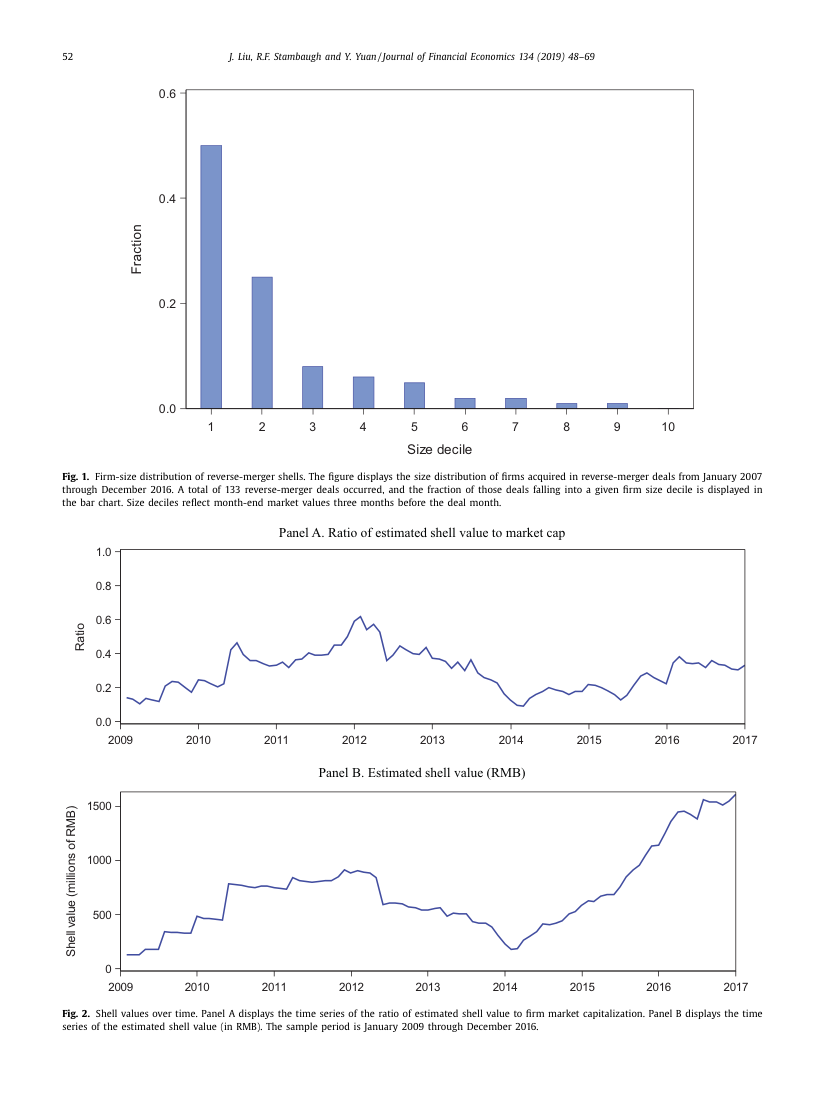

## Table A5 / Fig. A1 原文参照

**这是论文原图，仅作核查，不能作为本地数值复现结果。**

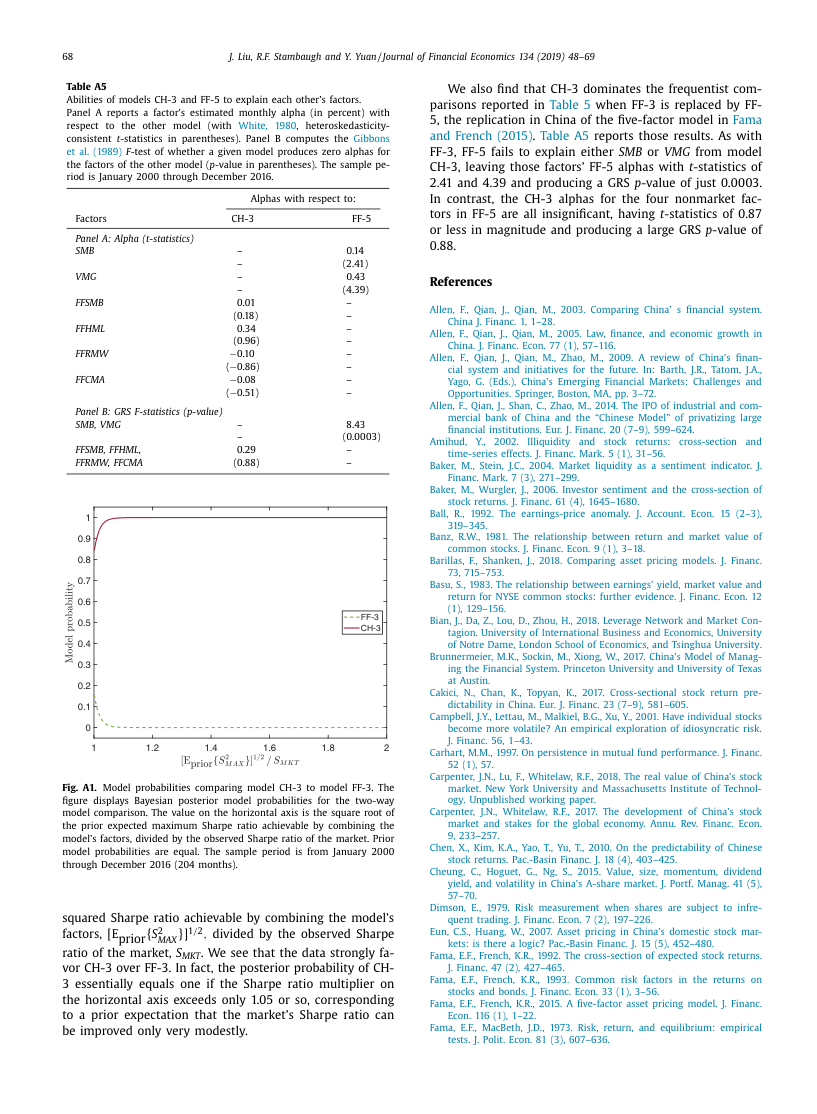